# Laboratorio 10 – CC3045 Deep Learning (Tasks 1 y 2)
Explicabilidad: Grad-CAM/CAM sobre ResNet-18 (Task 1) y SHAP sobre un modelo de crédito (Task 2).
Todo el código usa PyTorch, NumPy y scikit-learn; Grad-CAM y CAM están escritos desde cero y la fórmula de Shapley de la Task 2.5 también.

In [1]:
import os, random, time, json, math, itertools, warnings
import numpy as np, pandas as pd
import torch, torch.nn as nn, torch.nn.functional as F
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from PIL import Image
from torchvision import models, transforms
from scipy.stats import spearmanr
warnings.filterwarnings("ignore")

# Semilla aleatoria (se reporta en el documento): SEED = 42
SEED = 42
def set_seed(s=SEED):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)
set_seed()
device = "cuda" if torch.cuda.is_available() else "cpu"
os.makedirs("figures", exist_ok=True); os.makedirs("results", exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 160, "savefig.bbox": "tight"})

RES = {}   # resultados numéricos que luego se insertan en el documento de Word
def save_res(): json.dump(RES, open("results/results_t1_t2.json", "w", encoding="utf8"), indent=1, default=float)
print("torch", torch.__version__, "| device:", device, "| SEED =", SEED)

torch 2.11.0+cu128 | device: cuda | SEED = 42


# Task 1 – Grad-CAM y CAM sobre ResNet-18

## Task 1.1 – Modelo, preprocesado e imágenes

In [2]:
# ResNet-18 con pesos preentrenados de ImageNet, en modo evaluación.
weights = models.ResNet18_Weights.IMAGENET1K_V1
model = models.resnet18(weights=weights).to(device).eval()
CLASSES = weights.meta["categories"]

# Preprocesado pedido: lado corto a 256, recorte central 224x224 y normalización por canal de ImageNet.
MEAN, STD = (0.485, 0.456, 0.406), (0.229, 0.224, 0.225)
geom = transforms.Compose([transforms.Resize(256), transforms.CenterCrop(224)])
to_tensor, normalize = transforms.ToTensor(), transforms.Normalize(MEAN, STD)

IMG_FILES = {
    "a": "images/a_objeto_centrado.jpg",     # (a) objeto claro y centrado
    "b": "images/b_gato_y_perro.jpg",        # (b) dos objetos de clases distintas
    "c": "images/c_sofa_en_el_campo.jpg",    # (c) objeto fuera de su contexto habitual
}
def load_image(key):
    pil224 = geom(Image.open(IMG_FILES[key]).convert("RGB"))          # PIL 224x224 (sin normalizar)
    x = normalize(to_tensor(pil224)).unsqueeze(0).to(device)          # tensor 1x3x224x224 normalizado
    return pil224, x
IM = {k: load_image(k) for k in IMG_FILES}

@torch.no_grad()
def predict(x):
    logits = model(x)[0]
    return logits, F.softmax(logits, dim=0)

RES["t1_1"] = {}
for k in "abc":
    logits, probs = predict(IM[k][1])
    top = probs.topk(5)
    RES["t1_1"][k] = [{"idx": int(i), "name": CLASSES[int(i)], "p": float(p)} for p, i in zip(top.values, top.indices)]
    print(f"Imagen ({k}):")
    for r in RES["t1_1"][k]: print(f"   {r['idx']:4d}  {r['name']:<28s} {r['p']:.4f}")

Imagen (a):
    257  Great Pyrenees               0.7927
    222  kuvasz                       0.0706
    207  golden retriever             0.0436
    258  Samoyed                      0.0232
    249  malamute                     0.0131
Imagen (b):
    208  Labrador retriever           0.3945
    209  Chesapeake Bay retriever     0.0497
    282  tiger cat                    0.0340
    159  Rhodesian ridgeback          0.0300
    162  beagle                       0.0288
Imagen (c):
    435  bathtub                      0.3606
    876  tub                          0.2887
    463  bucket                       0.0538
    412  ashcan                       0.0335
    730  plow                         0.0191


Recuadro (c): (54, 137, 184, 208) | fracción del área: 0.184


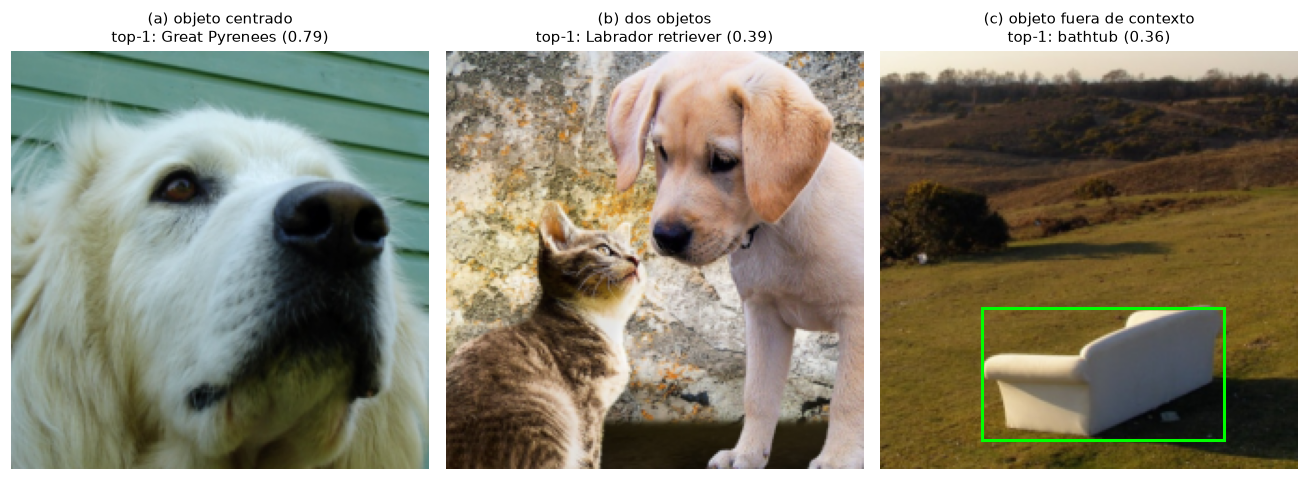

In [3]:
# Recuadro del objeto de la imagen (c) en coordenadas de la imagen de 224x224: (x0, y0, x1, y1), medido sobre la imagen recortada.
BOX_C = (54, 137, 184, 208)
RES["t1_1"]["box_c"] = BOX_C
RES["t1_1"]["box_c_area_frac"] = (BOX_C[2]-BOX_C[0])*(BOX_C[3]-BOX_C[1])/224**2
print("Recuadro (c):", BOX_C, "| fracción del área:", round(RES["t1_1"]["box_c_area_frac"], 4))

fig, ax = plt.subplots(1, 3, figsize=(12, 4.4))
titles = {"a": "(a) objeto centrado", "b": "(b) dos objetos", "c": "(c) objeto fuera de contexto"}
for a, k in zip(ax, "abc"):
    a.imshow(IM[k][0]); a.axis("off")
    a.set_title(f"{titles[k]}\ntop-1: {RES['t1_1'][k][0]['name']} ({RES['t1_1'][k][0]['p']:.2f})", fontsize=10)
x0, y0, x1, y1 = BOX_C
ax[2].add_patch(Rectangle((x0, y0), x1-x0, y1-y0, fill=False, ec="lime", lw=2))
plt.tight_layout(); plt.savefig("figures/t1_1_imagenes.png"); plt.show()

## Task 1.2 – Grad-CAM desde cero sobre `layer4`
Con $A^k\in\mathbb{R}^{7\times7}$ (512 canales) las activaciones de `layer4`:

$$\alpha_k^c=\frac{1}{Z}\sum_{i,j}\frac{\partial y^c}{\partial A^k_{ij}},\qquad L^c=\mathrm{ReLU}\Big(\sum_k\alpha_k^c A^k\Big)$$

El gradiente se obtiene retropropagando desde el **logit** $y^c$ (antes del softmax).

a {'cls': 257, 'name': 'Great Pyrenees', 'p': 0.792654812335968, 'logit': 13.268692970275879}
b {'cls': 208, 'name': 'Labrador retriever', 'p': 0.39454516768455505, 'logit': 9.694001197814941}
b2 {'cls': 282, 'name': 'tiger cat', 'p': 0.03402276709675789, 'logit': 7.243297576904297}
c {'cls': 435, 'name': 'bathtub', 'p': 0.36060023307800293, 'logit': 10.250008583068848}


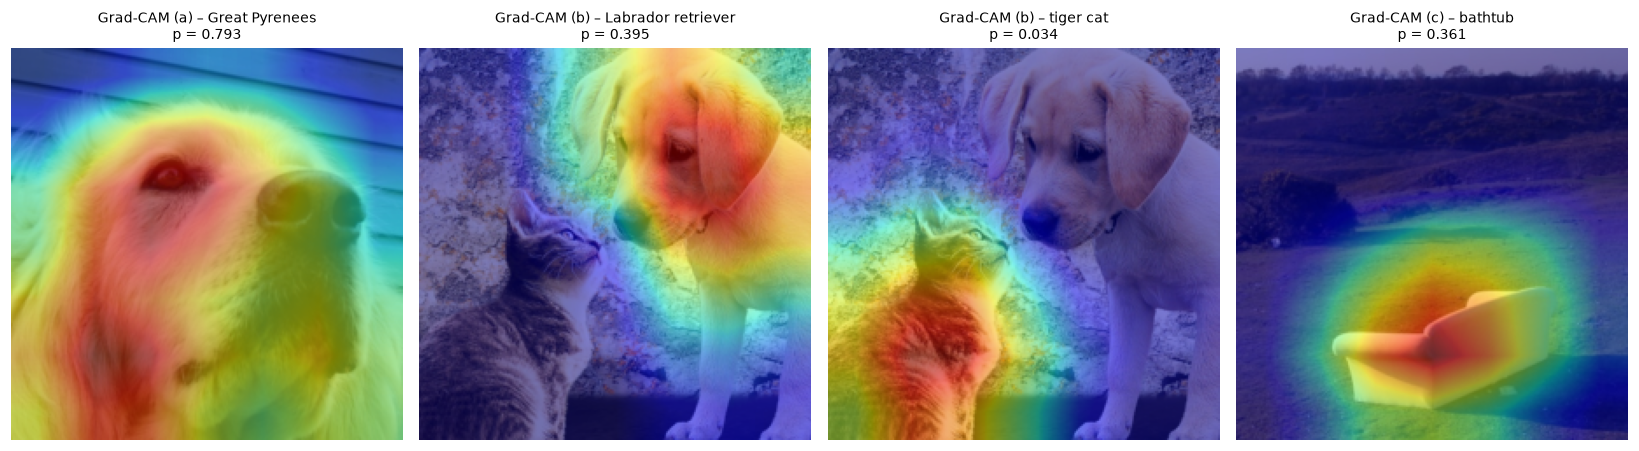

In [4]:
class GradCAM:
    """Grad-CAM con un hook de avance (activaciones A) y un hook de retroceso (dy^c/dA) sobre layer4."""
    def __init__(self, net, layer):
        self.net, self.A, self.dA = net, None, None
        self.h1 = layer.register_forward_hook(self._fwd)
        self.h2 = layer.register_full_backward_hook(self._bwd)
    def _fwd(self, module, inp, out):  self.A = out.detach()                 # A: 1x512x7x7
    def _bwd(self, module, gin, gout): self.dA = gout[0].detach()            # dy^c/dA: 1x512x7x7

    def __call__(self, x, c=None):
        self.net.zero_grad()
        logits = self.net(x)
        if c is None: c = int(logits.argmax(1))                              # clase de mayor probabilidad
        logits[0, c].backward()                                              # retropropaga desde el LOGIT y^c
        A, dA = self.A[0], self.dA[0]                                        # 512x7x7
        alpha = dA.mean(dim=(1, 2))                                          # alpha_k = promedio espacial del gradiente
        L_raw = (alpha[:, None, None] * A).sum(0)                            # sum_k alpha_k A^k (7x7), sin ReLU
        L = F.relu(L_raw)                                                    # L^c = ReLU(...)
        up = F.interpolate(L[None, None], size=(224, 224), mode="bilinear", align_corners=False)[0, 0]
        cam224 = (up - up.min()) / (up.max() - up.min() + 1e-12)             # normalización min-max
        return dict(c=c, logit=float(logits[0, c]), alpha=alpha, A=A, dA=dA, L_raw=L_raw, L=L, cam224=cam224)
    def remove(self): self.h1.remove(); self.h2.remove()

gradcam = GradCAM(model, model.layer4)

def overlay(ax, pil, cam, title, alpha=0.5):
    ax.imshow(pil); ax.imshow(cam.cpu().numpy(), cmap="jet", alpha=alpha, vmin=0, vmax=1); ax.axis("off"); ax.set_title(title, fontsize=9)

# Clase del "segundo objeto" de la imagen (b): la mejor clase de la otra especie (perros: 151-268, gatos: 281-285)
_, pb = predict(IM["b"][1]); top_b = int(pb.argmax())
rng_other = range(281, 286) if 151 <= top_b <= 268 else range(151, 269)
cls_b2 = max(rng_other, key=lambda i: float(pb[i]))

GC = {}
GC["a"]  = gradcam(IM["a"][1])
GC["b"]  = gradcam(IM["b"][1])
GC["b2"] = gradcam(IM["b"][1], c=cls_b2)
GC["c"]  = gradcam(IM["c"][1])
RES["t1_2"] = {k: {"cls": v["c"], "name": CLASSES[v["c"]], "p": float(predict(IM[k[0]][1])[1][v["c"]]), "logit": v["logit"]} for k, v in GC.items()}
for k, v in RES["t1_2"].items(): print(k, v)

fig, ax = plt.subplots(1, 4, figsize=(15, 4.2))
for a, k, im in zip(ax, ["a", "b", "b2", "c"], ["a", "b", "b", "c"]):
    r = RES["t1_2"][k]
    overlay(a, IM[im][0], GC[k]["cam224"], f"Grad-CAM ({im}) – {r['name']}\np = {r['p']:.3f}")
plt.tight_layout(); plt.savefig("figures/t1_2_gradcam.png"); plt.show()

## Task 1.3 – CAM desde los pesos de `fc` y verificaciones
$M^c_{ij}=\sum_k w^c_kA^k_{ij}$, y como el modelo termina en promedio global + lineal: $y^c=\frac1Z\sum_{ij}M^c_{ij}+b_c$ con $Z=49$.

img |  (1/Z)ΣM + b    logit y^c  |err| (b) |  max|Z·L − M| | max|err| ReLU+norm
  a |    13.268692    13.268693   9.54e-07 |      2.86e-06 |           1.19e-07
  b |     9.694000     9.694001   9.54e-07 |      3.81e-06 |           1.19e-07
 b2 |     7.243298     7.243298   0.00e+00 |      3.81e-06 |           1.19e-07
  c |    10.250010    10.250009   9.54e-07 |      3.81e-06 |           5.96e-08


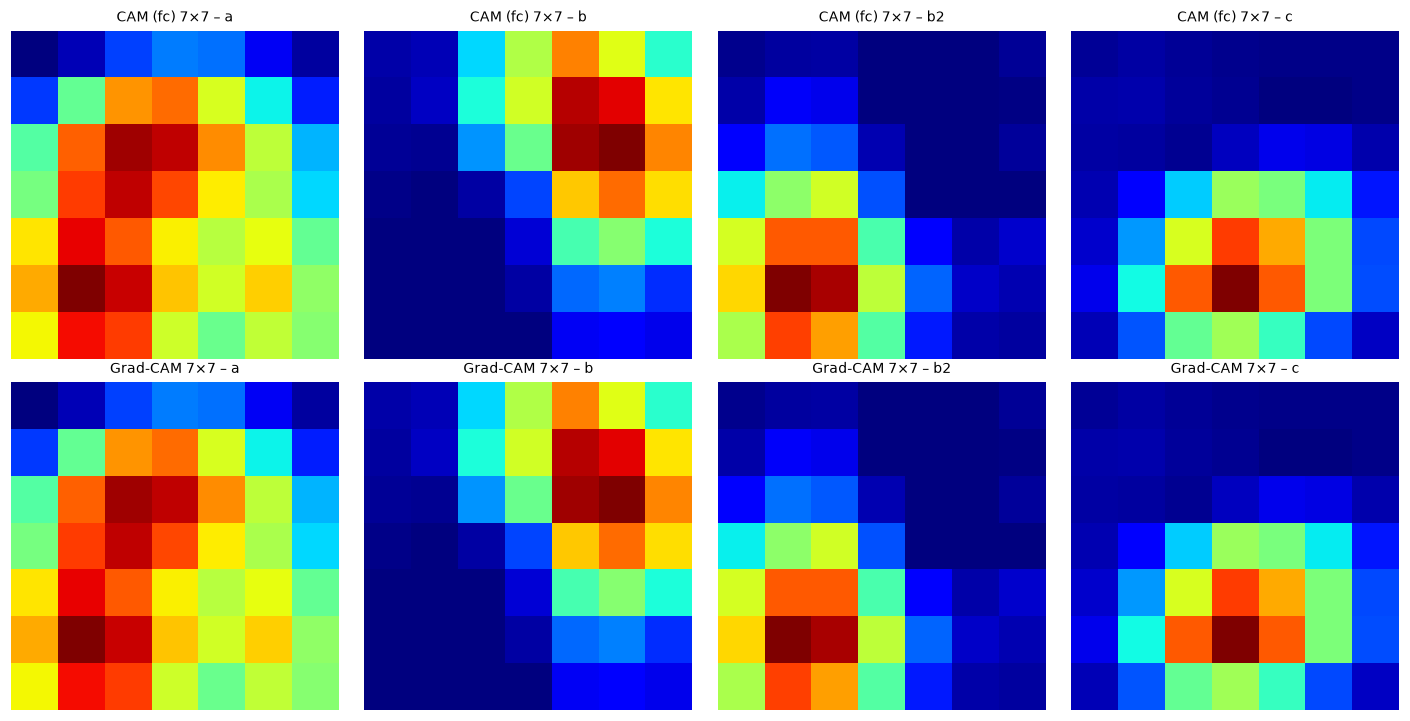

In [5]:
W, bias = model.fc.weight.detach(), model.fc.bias.detach()     # 1000x512, 1000
Z = 49
def reduce_map(m):                                              # ReLU + normalización min-max
    m = F.relu(m); return (m - m.min()) / (m.max() - m.min() + 1e-12)

RES["t1_3"] = {}
CAMS = {}
print(f"{'img':>3} | {'(1/Z)ΣM + b':>12} {'logit y^c':>12} {'|err| (b)':>10} | {'max|Z·L − M|':>13} | {'max|err| ReLU+norm':>18}")
for k in ["a", "b", "b2", "c"]:
    g = GC[k]; c = g["c"]
    M = torch.einsum("k,kij->ij", W[c], g["A"])                                  # (a) CAM sin gradientes
    score = M.sum() / Z + bias[c]                                                # (b) descomposición del puntaje
    err_b = abs(float(score) - g["logit"])
    err_c = float((Z * g["L_raw"] - M).abs().max())                              # (c) Z·L^c (sin ReLU ni norm.) vs M^c
    err_d = float((reduce_map(g["L_raw"]) - reduce_map(M)).abs().max())          # (d) tras ReLU + min-max
    RES["t1_3"][k] = dict(score=float(score), logit=g["logit"], err_b=err_b, err_c=err_c, err_d=err_d)
    CAMS[k] = M
    print(f"{k:>3} | {float(score):12.6f} {g['logit']:12.6f} {err_b:10.2e} | {err_c:13.2e} | {err_d:18.2e}")

fig, ax = plt.subplots(2, 4, figsize=(13, 6.6))
for j, k in enumerate(["a", "b", "b2", "c"]):
    ax[0, j].imshow(reduce_map(CAMS[k]).cpu(), cmap="jet", vmin=0, vmax=1); ax[0, j].set_title(f"CAM (fc) 7×7 – {k}", fontsize=9)
    ax[1, j].imshow(reduce_map(GC[k]["L_raw"]).cpu(), cmap="jet", vmin=0, vmax=1); ax[1, j].set_title(f"Grad-CAM 7×7 – {k}", fontsize=9)
    ax[0, j].axis("off"); ax[1, j].axis("off")
plt.tight_layout(); plt.savefig("figures/t1_3_cam_vs_gradcam.png"); plt.show()

## Task 1.4 – Análisis con los resultados propios

### (a) $\alpha_k^c$ numérico frente a $w_k^c/Z$ (imagen (a))

In [6]:
g, c = GC["a"], GC["a"]["c"]
top5 = W[c].topk(5).indices                                    # cinco canales de mayor peso w_k^c
rows = []
for k in top5.tolist():
    a_num, a_th = float(g["alpha"][k]), float(W[c, k] / Z)
    rows.append(dict(canal=k, w=float(W[c, k]), alpha=a_num, w_sobre_Z=a_th, err_rel=abs(a_num - a_th) / abs(a_th)))
df_alpha = pd.DataFrame(rows); print(df_alpha.to_string(index=False, float_format=lambda v: f"{v:.8g}"))
# ¿es dy^c/dA_ij^k realmente igual en las 49 posiciones? dispersión espacial del gradiente por canal
spread = (g["dA"] - (W[c] / Z)[:, None, None]).abs().amax()
print("max |dy/dA_ij^k − w_k/Z| sobre los 512 canales y 49 posiciones:", float(spread))
print("max error relativo de alpha sobre los 512 canales:", float(((g['alpha'] - W[c]/Z).abs() / (W[c]/Z).abs()).max()))
RES["t1_4a"] = dict(rows=rows, spread=float(spread), max_rel_all=float(((g['alpha'] - W[c]/Z).abs() / (W[c]/Z).abs()).max()), cls=c)

 canal          w        alpha    w_sobre_Z       err_rel
    31 0.30468294 0.0062180185 0.0062180189 7.4889011e-08
   242 0.22929093 0.0046794065 0.0046794065             0
   362 0.22662991 0.0046250997 0.0046251002 1.0068134e-07
   127 0.20768896 0.0042385501 0.0042385501             0
    83 0.20473976 0.0041783624 0.0041783624             0
max |dy/dA_ij^k − w_k/Z| sobre los 512 canales y 49 posiciones: 0.0
max error relativo de alpha sobre los 512 canales: 1.7372512672864104e-07


### (b) Imagen (b): ¿discrimina el mapa entre las dos clases?

{'iou224': 0.0, 'iou7': 0.0, 'cls1': 'Labrador retriever', 'cls2': 'tiger cat', 'centroid1': (155.7541046142578, 78.37948608398438), 'centroid2': (67.94343566894531, 156.73178100585938), 'p1': 0.39454516768455505, 'p2': 0.03402276709675789, 'corr': -0.6708921518390946}


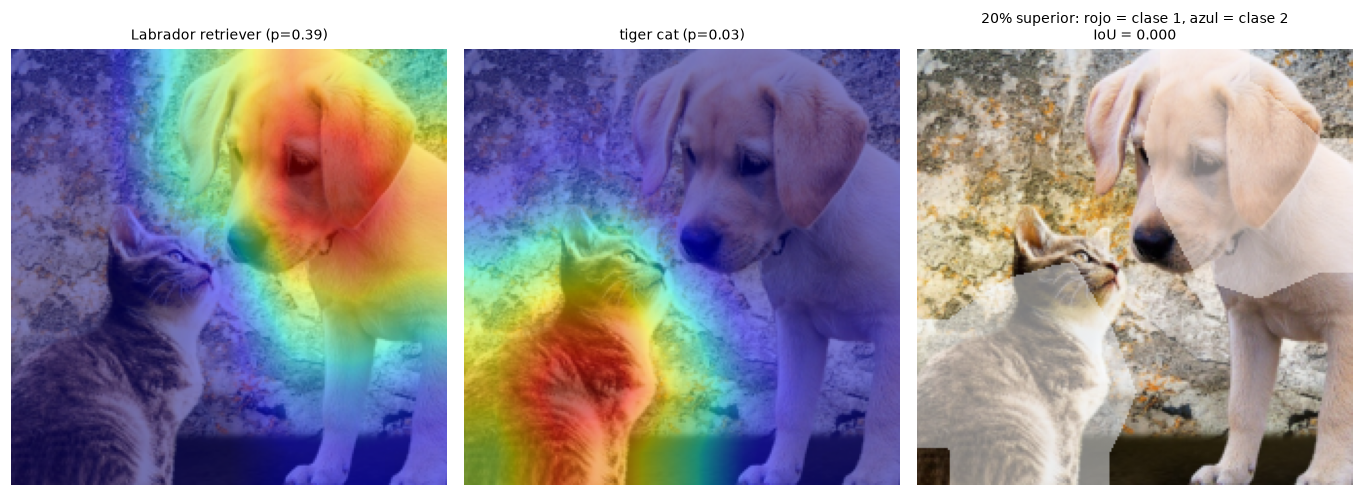

In [7]:
def top_set(m, frac=0.20):
    thr = torch.quantile(m.flatten(), 1 - frac); return m >= thr
def iou(a, b): return float((a & b).sum() / (a | b).sum())
m1, m2 = GC["b"]["cam224"], GC["b2"]["cam224"]
iou224 = iou(top_set(m1), top_set(m2))
# mismo cálculo sobre el mapa original 7x7 (20% de 49 celdas = 10 celdas)
l1, l2 = reduce_map(GC["b"]["L_raw"]), reduce_map(GC["b2"]["L_raw"])
k10 = lambda m: torch.zeros(49, dtype=torch.bool, device=m.device).scatter_(0, m.flatten().topk(10).indices, True)
iou7 = iou(k10(l1), k10(l2))
def centroid(m):
    ys, xs = torch.meshgrid(torch.arange(224, device=m.device), torch.arange(224, device=m.device), indexing="ij")
    return float((m * xs).sum() / m.sum()), float((m * ys).sum() / m.sum())
RES["t1_4b"] = dict(iou224=iou224, iou7=iou7, cls1=RES["t1_2"]["b"]["name"], cls2=RES["t1_2"]["b2"]["name"],
                    centroid1=centroid(m1), centroid2=centroid(m2),
                    p1=RES["t1_2"]["b"]["p"], p2=RES["t1_2"]["b2"]["p"],
                    corr=float(np.corrcoef(m1.flatten().cpu(), m2.flatten().cpu())[0, 1]))
print(RES["t1_4b"])

fig, ax = plt.subplots(1, 3, figsize=(12.5, 4.4))
overlay(ax[0], IM["b"][0], m1, f"{RES['t1_2']['b']['name']} (p={RES['t1_2']['b']['p']:.2f})")
overlay(ax[1], IM["b"][0], m2, f"{RES['t1_2']['b2']['name']} (p={RES['t1_2']['b2']['p']:.2f})")
ax[2].imshow(IM["b"][0]); ax[2].axis("off")
ax[2].imshow(np.ma.masked_where(~top_set(m1).cpu().numpy(), np.ones((224, 224))), cmap="Reds", alpha=0.5)
ax[2].imshow(np.ma.masked_where(~top_set(m2).cpu().numpy(), np.ones((224, 224))), cmap="Blues", alpha=0.5)
ax[2].set_title(f"20% superior: rojo = clase 1, azul = clase 2\nIoU = {iou224:.3f}", fontsize=9)
plt.tight_layout(); plt.savefig("figures/t1_4b_dos_clases.png"); plt.show()

### (c) Imagen (c): masa dentro del recuadro y prueba causal

original                     p(bathtub) = 0.3606 | top-1: bathtub (0.361)
fondo gris (solo objeto)     p(bathtub) = 0.0107 | top-1: paper towel (0.233)
objeto gris (solo fondo)     p(bathtub) = 0.0007 | top-1: alp (0.234)
p(studio couch) = 0.0003 (posición 86 de 1000)
masa dentro del recuadro: 0.4981 | fracción del área: 0.184 | razón: 2.708


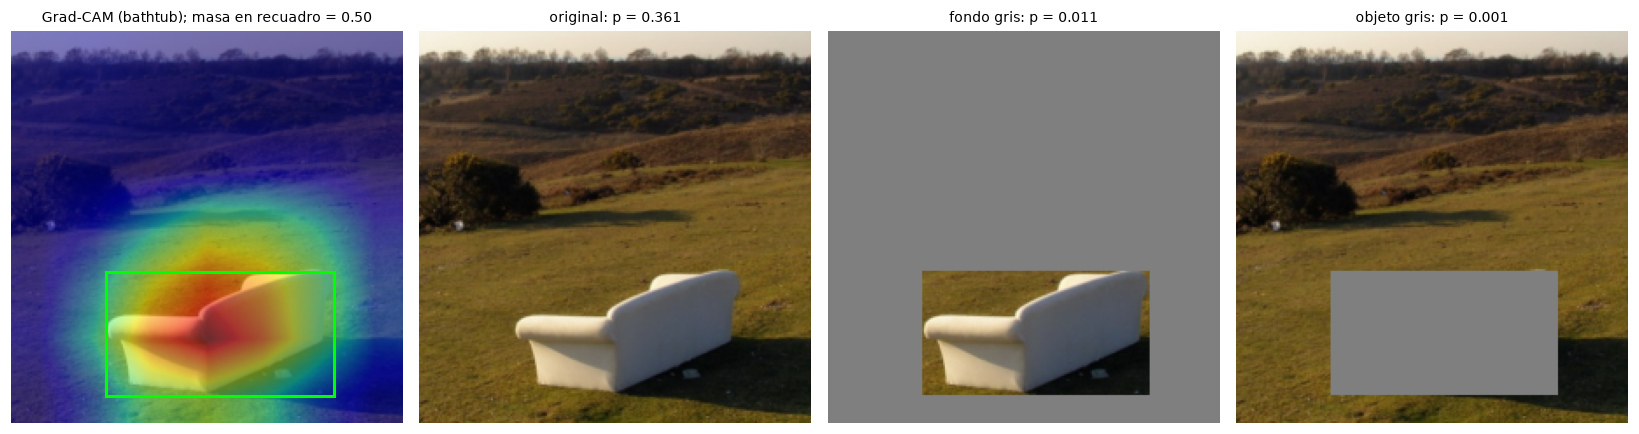

In [8]:
x0, y0, x1, y1 = BOX_C
cam = GC["c"]["cam224"]; c_c = GC["c"]["c"]
mass_in = float(cam[y0:y1, x0:x1].sum() / cam.sum())
area_frac = RES["t1_1"]["box_c_area_frac"]

def to_input(pil_or_arr):                                         # PIL/array [0,1] -> tensor normalizado
    return normalize(to_tensor(pil_or_arr)).unsqueeze(0).to(device) if isinstance(pil_or_arr, Image.Image) else normalize(pil_or_arr).unsqueeze(0).to(device)
base = to_tensor(IM["c"][0])                                      # 3x224x224 en [0,1]
gray = torch.full_like(base, 0.5)                                 # gris medio
outside_gray = gray.clone(); outside_gray[:, y0:y1, x0:x1] = base[:, y0:y1, x0:x1]     # fondo -> gris, objeto intacto
inside_gray = base.clone();  inside_gray[:, y0:y1, x0:x1] = 0.5                         # objeto -> gris, fondo intacto
res_c = {}
for name, img in [("original", base), ("fondo gris (solo objeto)", outside_gray), ("objeto gris (solo fondo)", inside_gray)]:
    _, p = predict(to_input(img)); top1 = int(p.argmax())
    res_c[name] = dict(p_clase=float(p[c_c]), top1=CLASSES[top1], p_top1=float(p[top1]))
    print(f"{name:<28s} p({CLASSES[c_c]}) = {float(p[c_c]):.4f} | top-1: {CLASSES[top1]} ({float(p[top1]):.3f})")
# clase ImageNet "esperada" del objeto: studio couch (831); se reporta su probabilidad y su posición en el ranking
_, p0 = predict(to_input(base)); rank_couch = int((p0 > p0[831]).sum()) + 1
print(f"p(studio couch) = {float(p0[831]):.4f} (posición {rank_couch} de 1000)")
RES["t1_4c"] = dict(p_couch=float(p0[831]), rank_couch=rank_couch, mass_in=mass_in, area_frac=area_frac, ratio=mass_in/area_frac, cls=CLASSES[c_c], tests=res_c)
print("masa dentro del recuadro:", round(mass_in, 4), "| fracción del área:", round(area_frac, 4), "| razón:", round(mass_in/area_frac, 3))

fig, ax = plt.subplots(1, 4, figsize=(15, 4.2))
overlay(ax[0], IM["c"][0], cam, f"Grad-CAM – {CLASSES[c_c]}")
ax[0].add_patch(Rectangle((x0, y0), x1-x0, y1-y0, fill=False, ec="lime", lw=2)); ax[0].set_title(f"Grad-CAM ({CLASSES[c_c]}); masa en recuadro = {mass_in:.2f}", fontsize=9)
for a, (name, img) in zip(ax[1:], [("original", base), ("fondo gris", outside_gray), ("objeto gris", inside_gray)]):
    a.imshow(img.permute(1, 2, 0).numpy()); a.axis("off")
    key = {"original": "original", "fondo gris": "fondo gris (solo objeto)", "objeto gris": "objeto gris (solo fondo)"}[name]
    a.set_title(f"{name}: p = {res_c[key]['p_clase']:.3f}", fontsize=9)
plt.tight_layout(); plt.savefig("figures/t1_4c_prueba_causal.png"); plt.show()
save_res()

# Task 2 – SHAP sobre German Credit

## Task 2.1 – Datos y modelo

In [9]:
from sklearn.datasets import fetch_openml
from sklearn.preprocessing import OrdinalEncoder
from sklearn.model_selection import train_test_split
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import accuracy_score, roc_auc_score
from sklearn.inspection import permutation_importance
import shap

try:
    datos = fetch_openml("credit-g", version=1, as_frame=True)
    X_raw, y_raw = datos.data.copy(), datos.target
    FUENTE = "fetch_openml"
except Exception as e:
    # En esta red el certificado de api.openml.org no es confiable para Python; se usa el mismo ARFF (OpenML data id 31, credit-g v1),
    # descargado de https://www.openml.org/data/v1/download/31/credit-g.arff, con las categorías en el orden declarado en el ARFF.
    print("fetch_openml falló:", type(e).__name__, "-> se usa data/credit-g.arff")
    from scipy.io import arff
    raw, meta = arff.loadarff("data/credit-g.arff")
    df = pd.DataFrame(raw)
    for c in meta.names():
        if meta[c][0] == "nominal":
            df[c] = pd.Categorical(df[c].str.decode("utf-8"), categories=list(meta[c][1]))
    y_raw = df.pop("class"); X_raw = df
    FUENTE = "ARFF local (OpenML data id 31)"
print("fuente de los datos:", FUENTE)
y = (y_raw.astype(str) == "good").astype(int).to_numpy()                      # good = 1, bad = 0
cat_cols = [c for c in X_raw.columns if str(X_raw[c].dtype) == "category"]
num_cols = [c for c in X_raw.columns if c not in cat_cols]
print(len(X_raw), "solicitudes |", len(num_cols), "numéricas |", len(cat_cols), "categóricas |", "good:", int(y.sum()), "bad:", int((1-y).sum()))

# Codificador ordinal: los códigos son ARBITRARIOS (según el orden de las categorías); se tratan como numéricos (limitación)
enc = OrdinalEncoder(categories=[list(X_raw[c].cat.categories) for c in cat_cols]).fit(X_raw[cat_cols])
X = X_raw.copy()
X[cat_cols] = enc.transform(X_raw[cat_cols])
X = X.astype(float); FEATS = list(X.columns)

Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEED)
gbm = GradientBoostingClassifier(n_estimators=200, max_depth=3, random_state=SEED).fit(Xtr, ytr)
f_logodds = lambda D: gbm.decision_function(D)                    # salida del modelo en log-odds
acc = accuracy_score(yte, gbm.predict(Xte)); auc = roc_auc_score(yte, gbm.predict_proba(Xte)[:, 1])
RES["t2_1"] = dict(n=len(X), n_num=len(num_cols), n_cat=len(cat_cols), n_train=len(Xtr), n_test=len(Xte), acc=acc, auc=auc,
                   good_train=float(ytr.mean()), good_test=float(yte.mean()))
print(f"train={len(Xtr)} test={len(Xte)} | exactitud = {acc:.4f} | AUC = {auc:.4f}")

# Fondo de 100 instancias de entrenamiento elegidas al azar (se reutiliza en todo el Task 2)
rng = np.random.RandomState(SEED)
bg_idx = rng.choice(len(Xtr), 100, replace=False)
BG = Xtr.iloc[bg_idx]

fuente de los datos: fetch_openml
1000 solicitudes | 7 numéricas | 13 categóricas | good: 700 bad: 300
train=800 test=200 | exactitud = 0.7800 | AUC = 0.7685


## Task 2.2 – Valores SHAP (TreeSHAP intervencional, log-odds)

In [10]:
expl = shap.TreeExplainer(gbm, data=BG, feature_perturbation="interventional", model_output="raw")
phi = expl.shap_values(Xte)                                        # (200, 20) en log-odds
base = float(np.ravel(expl.expected_value)[0])
fx = f_logodds(Xte)                                                # f(x) en log-odds

# (a) eficiencia: base + sum phi_j = f(x)
eff_err = np.abs(base + phi.sum(1) - fx)
# (b) valor base = promedio de la salida del modelo sobre el fondo
base_bg = float(f_logodds(BG).mean())
print(f"(a) max |base + Σφ − f(x)| = {eff_err.max():.3e}  (media {eff_err.mean():.3e})")
print(f"(b) valor base SHAP = {base:.8f} | promedio f sobre el fondo = {base_bg:.8f} | dif = {abs(base-base_bg):.2e}")

# (c) importancia global y por permutación (AUC, 10 repeticiones)
I_shap = np.abs(phi).mean(0)
pi = permutation_importance(gbm, Xte, yte, scoring="roc_auc", n_repeats=10, random_state=SEED)
I_perm = pi.importances_mean
order_s, order_p = np.argsort(-I_shap), np.argsort(-I_perm)
rho = spearmanr(I_shap, I_perm).correlation
print("\nTop-5 |φ| medio:      ", [(FEATS[i], round(float(I_shap[i]), 4)) for i in order_s[:5]])
print("Top-5 permutación (AUC):", [(FEATS[i], round(float(I_perm[i]), 4)) for i in order_p[:5]])
print(f"Spearman entre los rankings completos: {rho:.4f}")
RES["t2_2"] = dict(eff_max=float(eff_err.max()), eff_mean=float(eff_err.mean()), base=base, base_bg=base_bg,
                   I_shap={FEATS[i]: float(I_shap[i]) for i in range(20)}, I_perm={FEATS[i]: float(I_perm[i]) for i in range(20)},
                   I_perm_std={FEATS[i]: float(pi.importances_std[i]) for i in range(20)},
                   top5_shap=[FEATS[i] for i in order_s[:5]], top5_perm=[FEATS[i] for i in order_p[:5]], spearman=float(rho))

(a) max |base + Σφ − f(x)| = 5.997e-08  (media 1.298e-08)
(b) valor base SHAP = 1.28564395 | promedio f sobre el fondo = 1.28564395 | dif = 0.00e+00



Top-5 |φ| medio:       [('checking_status', 0.7496), ('credit_amount', 0.4869), ('duration', 0.3933), ('savings_status', 0.3502), ('purpose', 0.3402)]
Top-5 permutación (AUC): [('checking_status', 0.1188), ('duration', 0.0724), ('credit_amount', 0.068), ('credit_history', 0.039), ('savings_status', 0.0304)]
Spearman entre los rankings completos: 0.7549


aprobado: posición 157 p = 0.9003 | rechazado: posición 180 p = 0.0997


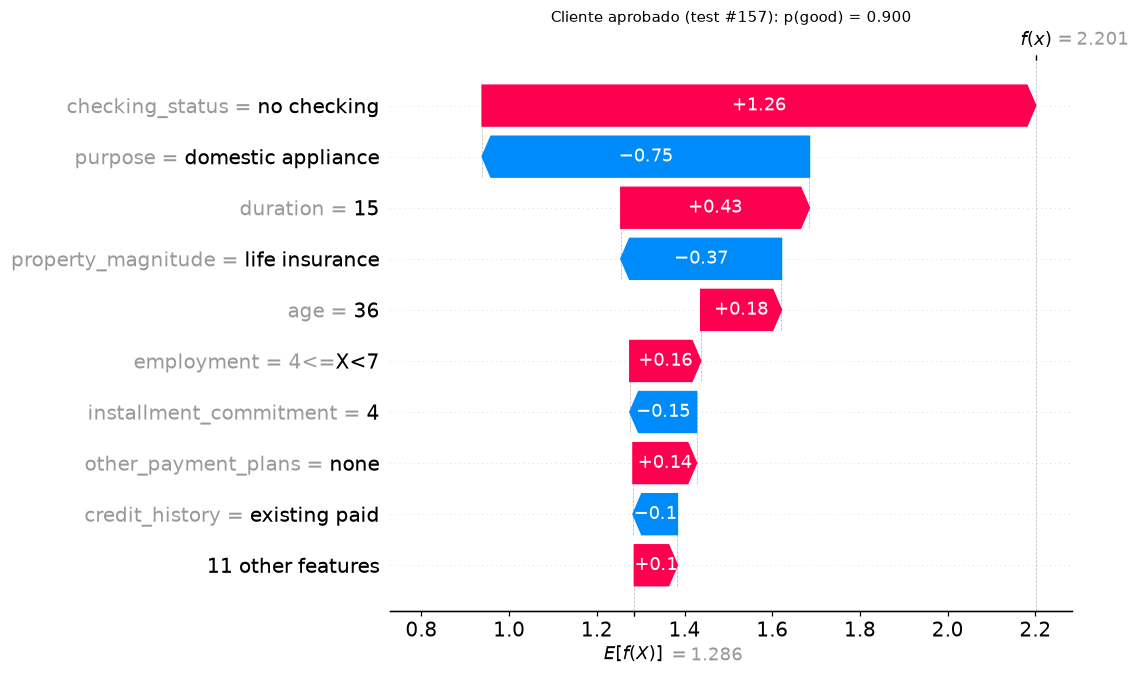

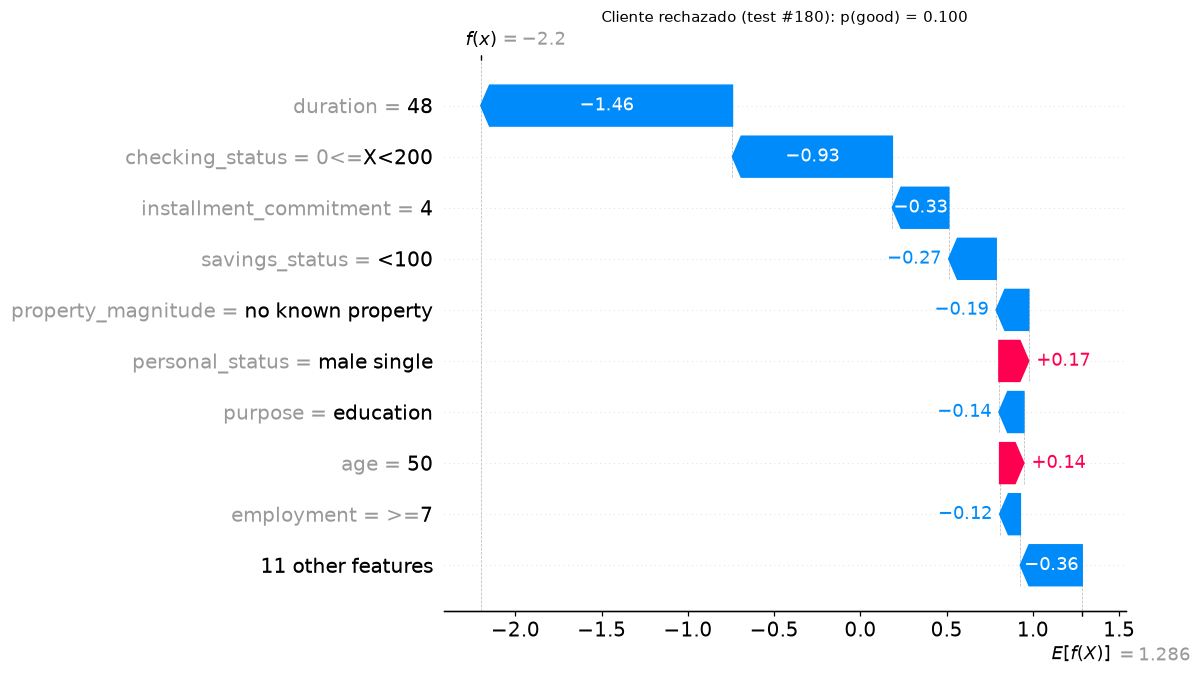

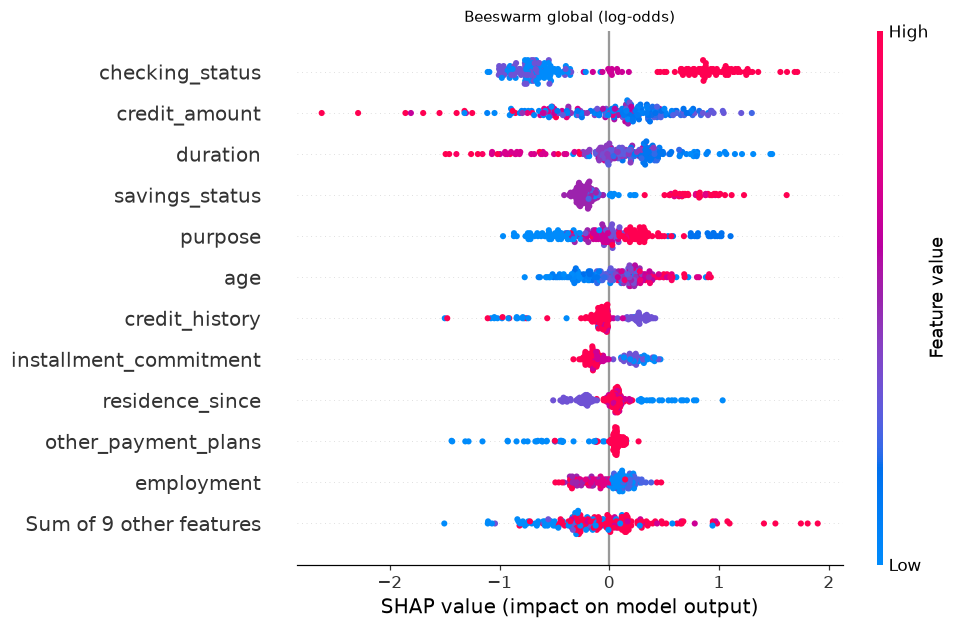

[{'feat': 'checking_status', 'valor': 'no checking', 'phi': 1.2623228674312121}, {'feat': 'purpose', 'valor': 'domestic appliance', 'phi': -0.746336517445743}, {'feat': 'duration', 'valor': '15', 'phi': 0.4300927376560867}]
[{'feat': 'duration', 'valor': '48', 'phi': -1.4585865248832852}, {'feat': 'checking_status', 'valor': '0<=X<200', 'phi': -0.9268442213558592}, {'feat': 'installment_commitment', 'valor': '4', 'phi': -0.326989728261251}]


In [11]:
# (d) clientes de prueba: p(good) > 0.8 (aprobado) y p(good) < 0.2 (rechazado)
p_te = gbm.predict_proba(Xte)[:, 1]
i_ok  = int(np.argmin(np.where(p_te > 0.8, np.abs(p_te - 0.9), np.inf)))      # el más cercano a 0.9 entre los >0.8
i_bad = int(np.argmin(np.where(p_te < 0.2, np.abs(p_te - 0.1), np.inf)))      # el más cercano a 0.1 entre los <0.2
print("aprobado: posición", i_ok, "p =", round(p_te[i_ok], 4), "| rechazado: posición", i_bad, "p =", round(p_te[i_bad], 4))

def decode_row(i):                                                 # valores originales (categorías decodificadas)
    return X_raw.loc[Xte.index[i]]
def waterfall(i, fname, title):
    row = decode_row(i)
    names = [f"{f} = {row[f]}" for f in FEATS]
    e = shap.Explanation(values=phi[i], base_values=base, data=None, feature_names=names)
    plt.figure(); shap.plots.waterfall(e, max_display=10, show=False); plt.title(title, fontsize=10)
    plt.savefig(fname); plt.show()
waterfall(i_ok,  "figures/t2_2_waterfall_aprobado.png",  f"Cliente aprobado (test #{i_ok}): p(good) = {p_te[i_ok]:.3f}")
waterfall(i_bad, "figures/t2_2_waterfall_rechazado.png", f"Cliente rechazado (test #{i_bad}): p(good) = {p_te[i_bad]:.3f}")

plt.figure(); shap.plots.beeswarm(shap.Explanation(values=phi, base_values=np.full(len(phi), base), data=Xte.values, feature_names=FEATS),
                                  max_display=12, show=False)
plt.title("Beeswarm global (log-odds)", fontsize=10); plt.savefig("figures/t2_2_beeswarm.png"); plt.show()

def top3(i):
    order = np.argsort(-np.abs(phi[i]))[:3]; row = decode_row(i)
    return [dict(feat=FEATS[j], valor=str(row[FEATS[j]]), phi=float(phi[i, j])) for j in order]
RES["t2_2"].update(i_ok=i_ok, i_bad=i_bad, p_ok=float(p_te[i_ok]), p_bad=float(p_te[i_bad]), fx_ok=float(fx[i_ok]), fx_bad=float(fx[i_bad]),
                   top3_ok=top3(i_ok), top3_bad=top3(i_bad), row_bad={k: str(v) for k, v in decode_row(i_bad).items()},
                   row_ok={k: str(v) for k, v in decode_row(i_ok).items()})
print(RES["t2_2"]["top3_ok"]); print(RES["t2_2"]["top3_bad"]); save_res()

## Task 2.3 – Variable redundante
Se duplica con ruido la variable numérica de mayor $I_j$: $x_{dup}=x+0.05\,\sigma_x\,\epsilon$, $\epsilon\sim\mathcal N(0,1)$, y se reentrena con 21 variables.

In [12]:
num_imp = {f: I_shap[FEATS.index(f)] for f in num_cols}
v_dup = max(num_imp, key=num_imp.get)
sigma_x = float(Xtr[v_dup].std())                                  # desviación estándar de la variable (entrenamiento)
rs = np.random.RandomState(SEED)
eps_all = rs.randn(len(X))                                         # mismo ruido para cada fila del conjunto (se parte con los mismos índices)
X21 = X.copy(); X21[v_dup + "_copia"] = X[v_dup].values + 0.05 * sigma_x * eps_all
X21tr, X21te = X21.loc[Xtr.index], X21.loc[Xte.index]
gbm21 = GradientBoostingClassifier(n_estimators=200, max_depth=3, random_state=SEED).fit(X21tr, ytr)
acc21 = accuracy_score(yte, gbm21.predict(X21te)); auc21 = roc_auc_score(yte, gbm21.predict_proba(X21te)[:, 1])
print("variable duplicada:", v_dup, "| σ_x =", round(sigma_x, 3), "| exactitud", round(acc21, 4), "| AUC", round(auc21, 4))

FEATS21 = list(X21.columns); j0, j1 = FEATS21.index(v_dup), FEATS21.index(v_dup + "_copia")
BG21 = X21tr.iloc[bg_idx]
e_int = shap.TreeExplainer(gbm21, data=BG21, feature_perturbation="interventional", model_output="raw")
e_tpd = shap.TreeExplainer(gbm21, feature_perturbation="tree_path_dependent", model_output="raw")
phi_int, phi_tpd = e_int.shap_values(X21te), e_tpd.shap_values(X21te)
tab = {}
for name, P in [("interventional", phi_int), ("tree_path_dependent", phi_tpd)]:
    tab[name] = dict(orig=float(np.abs(P[:, j0]).mean()), copia=float(np.abs(P[:, j1]).mean()), suma=float(np.abs(P[:, j0] + P[:, j1]).mean()))
tab["I_orig_sin_copia"] = float(I_shap[FEATS.index(v_dup)])
print(pd.DataFrame(tab).T.to_string(float_format=lambda v: f"{v:.4f}"))
for name, P in [("interventional", phi_int), ("tree_path_dependent", phi_tpd)]:
    tab[name]["frac_signo_opuesto"] = float((np.sign(P[:, j0]) != np.sign(P[:, j1])).mean())     # instancias con φ_orig y φ_copia de signo opuesto
    print(name, "fracción de instancias con signos opuestos:", round(tab[name]["frac_signo_opuesto"], 3))
print("corr(x, copia) =", float(np.corrcoef(X21[v_dup], X21[v_dup + '_copia'])[0, 1]))
RES["t2_3"] = dict(var=v_dup, sigma=sigma_x, acc=acc21, auc=auc21, tab=tab, corr=float(np.corrcoef(X21[v_dup], X21[v_dup + '_copia'])[0, 1]),
                   I_shap21={FEATS21[i]: float(np.abs(phi_int[:, i]).mean()) for i in range(21)})
save_res()

variable duplicada: credit_amount | σ_x = 2771.002 | exactitud 0.775 | AUC 0.7696


                      orig  copia   suma
interventional      0.3051 0.2845 0.4368
tree_path_dependent 0.2714 0.2386 0.4247
I_orig_sin_copia    0.4869 0.4869 0.4869
interventional fracción de instancias con signos opuestos: 0.495
tree_path_dependent fracción de instancias con signos opuestos: 0.44
corr(x, copia) = 0.9988464689259131


## Task 2.4 – KernelSHAP frente a TreeSHAP

In [13]:
n_inst, n_samples = 10, 2000
np.random.seed(SEED)                                              # KernelSHAP muestrea coaliciones al azar
Xk = Xte.iloc[:n_inst]
t24 = []
for nb in [10, 50, 100]:
    bg = BG.iloc[:nb]
    t0 = time.perf_counter()
    ke = shap.KernelExplainer(f_logodds, bg, link="identity")
    phi_k = ke.shap_values(Xk, nsamples=n_samples, silent=True)
    t_k = time.perf_counter() - t0
    t0 = time.perf_counter()
    te = shap.TreeExplainer(gbm, data=bg, feature_perturbation="interventional", model_output="raw")
    phi_t = te.shap_values(Xk)
    t_t = time.perf_counter() - t0
    mae = float(np.abs(phi_k - phi_t).mean())
    t24.append(dict(fondo=nb, mae=mae, t_kernel=t_k, t_tree=t_t, mae_rel=mae / float(np.abs(phi_t).mean())))
    print(f"fondo {nb:3d}: MAE = {mae:.5f} | KernelSHAP {t_k:7.2f} s | TreeSHAP {t_t:6.3f} s")
RES["t2_4"] = dict(rows=t24, n_inst=n_inst, n_samples=n_samples); save_res()

fondo  10: MAE = 0.04169 | KernelSHAP    0.34 s | TreeSHAP  0.004 s


fondo  50: MAE = 0.03613 | KernelSHAP    1.19 s | TreeSHAP  0.010 s


fondo 100: MAE = 0.03825 | KernelSHAP    2.69 s | TreeSHAP  0.014 s


## Task 2.5 – Shapley exacto escrito a mano (modelo de 6 variables numéricas)
$$\phi_i=\sum_{S\subseteq N\setminus\{i\}}\frac{|S|!\,(n-|S|-1)!}{n!}\big[v(S\cup\{i\})-v(S)\big],\qquad v(S)=\frac1{|B|}\sum_{b\in B}f\big(x_S,\,b_{\bar S}\big)$$

In [14]:
F6 = ["duration", "credit_amount", "installment_commitment", "residence_since", "age", "existing_credits"]
gbm6 = GradientBoostingClassifier(n_estimators=200, max_depth=3, random_state=SEED).fit(Xtr[F6], ytr)
f6 = lambda D: gbm6.decision_function(D)
BG6 = Xtr[F6].iloc[bg_idx[:50]]                                    # fondo de 50 instancias
n = len(F6); fact = math.factorial

def shapley_exact(x, bg, f):
    """phi_i exacto enumerando las 2^n coaliciones. x: vector (n,), bg: matriz (m, n)."""
    m = len(bg)
    # v[mask]: promedio de f sobre el fondo, fijando en x las variables de S (bit i de mask) y tomando el resto del fondo
    batch = np.empty((2**n * m, n))
    for mask in range(2**n):
        Z_ = bg.copy()
        for i in range(n):
            if mask >> i & 1: Z_[:, i] = x[i]
        batch[mask*m:(mask+1)*m] = Z_
    out = f(pd.DataFrame(batch, columns=F6)).reshape(2**n, m)
    v = out.mean(1)                                                # v(S) para las 64 coaliciones
    phi_ = np.zeros(n)
    for i in range(n):
        for mask in range(2**n):
            if mask >> i & 1: continue                             # S no contiene a i
            s = bin(mask).count("1")
            w = fact(s) * fact(n - s - 1) / fact(n)                # peso con factoriales
            phi_[i] += w * (v[mask | (1 << i)] - v[mask])
    return phi_, v

te6 = shap.TreeExplainer(gbm6, data=BG6, feature_perturbation="interventional", model_output="raw")
X5 = Xte[F6].iloc[:5]
rows = []; errs = []; effs = []
for r in range(5):
    x = X5.iloc[r].values
    ph, v = shapley_exact(x, BG6.values, f6)
    ph_tree = te6.shap_values(X5.iloc[[r]])[0]
    errs.append(np.abs(ph - ph_tree).max())
    effs.append(abs(ph.sum() - (v[-1] - v[0])))                    # v(N) − v(∅)
    rows.append(dict(inst=r, **{F6[i]: ph[i] for i in range(n)}, v_N=v[-1], v_vacio=v[0], f_x=float(f6(X5.iloc[[r]])[0]),
                     err_vs_tree=errs[-1], err_eff=effs[-1]))
df25 = pd.DataFrame(rows); print(df25.to_string(float_format=lambda v: f"{v:.5f}"))
print(f"error máximo vs TreeSHAP intervencional: {max(errs):.3e} | error máximo de eficiencia: {max(effs):.3e}")
RES["t2_5"] = dict(rows=rows, err_max=float(max(errs)), eff_max=float(max(effs)), n_coal=2**n, feats=F6); save_res()

   inst  duration  credit_amount  installment_commitment  residence_since      age  existing_credits      v_N  v_vacio      f_x  err_vs_tree  err_eff
0     0  -0.39139        0.42493                -0.04639         -0.14353  0.30907           0.09945  1.34244  1.09030  1.34244      0.00000  0.00000
1     1  -1.21376        0.14613                -0.02092         -0.12586 -0.37093          -0.03818 -0.53322  1.09030 -0.53322      0.00000  0.00000
2     2   0.06484       -1.24138                 0.06115          0.02450  0.51463          -0.04205  0.47200  1.09030  0.47200      0.00000  0.00000
3     3   0.51909        0.73326                -0.01613         -0.16585  0.44326          -0.06537  2.53856  1.09030  2.53856      0.00000  0.00000
4     4   0.56554       -1.35627                 0.04663          0.00064  0.86990          -0.04567  1.17107  1.09030  1.17107      0.00000  0.00000
error máximo vs TreeSHAP intervencional: 2.130e-08 | error máximo de eficiencia: 7.772e-16


## Task 2.6 – Cálculos para el análisis

In [15]:
# (a) cliente rechazado: efectos en probabilidad vs. log-odds
sig = lambda z: 1 / (1 + np.exp(-z))
j_phi = phi[i_bad]; f_bad = float(fx[i_bad])
p_x, p_base = float(sig(f_bad)), float(sig(base))
eff_p = {FEATS[j]: float(sig(base + j_phi[j]) - sig(base)) for j in range(20)}
sum_eff_p = sum(eff_p.values())
print(f"p(x) = {p_x:.4f} | σ(φ0) = {p_base:.4f} | p(x) − σ(φ0) = {p_x - p_base:.4f} | Σ efectos individuales = {sum_eff_p:.4f}")
print(sorted(eff_p.items(), key=lambda t: t[1])[:4], "...", sorted(eff_p.items(), key=lambda t: t[1])[-3:])

# (b) mayor diferencia de posición entre ranking SHAP y ranking de permutación
rk_s = pd.Series(I_shap, index=FEATS).rank(ascending=False); rk_p = pd.Series(I_perm, index=FEATS).rank(ascending=False)
diff = (rk_s - rk_p); v_rank = diff.abs().idxmax()
corr_all = X.corr(method="spearman")[v_rank].drop(v_rank); big = corr_all.abs().sort_values(ascending=False)[:4]
print(f"mayor diferencia: {v_rank} | rango SHAP {int(rk_s[v_rank])} | rango perm. {int(rk_p[v_rank])}")
print("correlaciones (Spearman) con las demás:", {k: round(float(corr_all[k]), 3) for k in big.index})
print("perm.:", I_perm[FEATS.index(v_rank)], "±", pi.importances_std[FEATS.index(v_rank)], "| |φ| medio:", I_shap[FEATS.index(v_rank)])
# evidencia adicional: ¿el modelo usa la variable pero no le sirve para generalizar?
pi_tr = permutation_importance(gbm, Xtr, ytr, scoring="roc_auc", n_repeats=10, random_state=SEED)
jr = FEATS.index(v_rank)
auc_uni_te = roc_auc_score(yte, Xte[v_rank]); auc_uni_tr = roc_auc_score(ytr, Xtr[v_rank])
print(f"perm. en ENTRENAMIENTO: {pi_tr.importances_mean[jr]:.4f} ± {pi_tr.importances_std[jr]:.4f} | impureza (feature_importances_): {gbm.feature_importances_[jr]:.4f}")
print(f"AUC univariado train = {auc_uni_tr:.3f} | test = {auc_uni_te:.3f} | spearman con y (test): {spearmanr(Xte[v_rank], yte).correlation:.3f}")
# variantes: top-5 de rangos con diferencias
print(diff.abs().sort_values(ascending=False)[:5])

# (d) tiempos: una predicción sobre 100 instancias, estimaciones para 2^20 y 2^60 evaluaciones
reps = 200; D100 = Xte.iloc[:100]
t0 = time.perf_counter()
for _ in range(reps): gbm.decision_function(D100)
t100 = (time.perf_counter() - t0) / reps
t_exact_20 = 2**20 * t100                                          # 2^20 evaluaciones de v(S), cada una = 1 predicción sobre el fondo (100)
t_kernel_inst = t24[-1]["t_kernel"] / n_inst                       # KernelSHAP por instancia (fondo 100)
secs_year = 365.25 * 24 * 3600
years_60 = 2**60 * 1e-6 / secs_year
print(f"t(100 predicciones) = {t100*1e3:.3f} ms | 2^20 · t100 = {t_exact_20:.1f} s = {t_exact_20/3600:.2f} h | KernelSHAP/instancia = {t_kernel_inst:.2f} s | 2^60 µs = {years_60:.3e} años")
# modelo de costo de KernelSHAP: evaluaciones = nsamples × |fondo|
evals = [n_samples * r["fondo"] for r in t24]
RES["t2_6"] = dict(p_x=p_x, p_base=p_base, sum_eff_p=sum_eff_p, eff_p=eff_p, f_bad=f_bad, base=base,
                   v_rank=v_rank, rk_s=int(rk_s[v_rank]), rk_p=int(rk_p[v_rank]), corr_top={k: float(corr_all[k]) for k in big.index},
                   rank_table={f: [int(rk_s[f]), int(rk_p[f])] for f in FEATS}, diff_top=diff.abs().sort_values(ascending=False)[:5].to_dict(),
                   perm_train=float(pi_tr.importances_mean[jr]), perm_train_std=float(pi_tr.importances_std[jr]), gini=float(gbm.feature_importances_[jr]),
                   auc_uni_tr=float(auc_uni_tr), auc_uni_te=float(auc_uni_te), spearman_y=float(spearmanr(Xte[v_rank], yte).correlation),
                   perm_te=float(I_perm[jr]), perm_te_std=float(pi.importances_std[jr]), shap_v=float(I_shap[jr]),
                   t100=t100, t_exact_20=t_exact_20, t_kernel_inst=t_kernel_inst, years_60=years_60, evals=evals)
save_res()

p(x) = 0.0997 | σ(φ0) = 0.7834 | p(x) − σ(φ0) = -0.6837 | Σ efectos individuales = -0.7236
[('duration', -0.32653717351831646), ('checking_status', -0.19465911897926313), ('installment_commitment', -0.060556693038553266), ('savings_status', -0.050231272126840976)] ... [('other_payment_plans', 0.006899327312453574), ('age', 0.022846505218508506), ('personal_status', 0.02782052443807881)]
mayor diferencia: residence_since | rango SHAP 9 | rango perm. 18
correlaciones (Spearman) con las demás: {'age': 0.235, 'employment': 0.228, 'own_telephone': 0.095, 'credit_history': -0.083}
perm.: -0.002690476190476154 ± 0.011751296546404652 | |φ| medio: 0.1716842689682263


perm. en ENTRENAMIENTO: 0.0108 ± 0.0011 | impureza (feature_importances_): 0.0210
AUC univariado train = 0.501 | test = 0.487 | spearman con y (test): -0.022
residence_since    9.0
purpose            7.0
age                7.0
housing            6.0
foreign_worker     6.0
dtype: float64
t(100 predicciones) = 0.479 ms | 2^20 · t100 = 502.0 s = 0.14 h | KernelSHAP/instancia = 0.27 s | 2^60 µs = 3.653e+04 años
